# Pescadores Web: doações, demanda e risco de falta de itens

Análise com **CRISP-DM**, ligada ao TCC de Felipe Barbosa Vieira e Calebe Mendes Bezerra.
Código e documentação preparados com auxílio de IA; revisão e compreensão pela equipe são necessárias.

> **Todos os dados são simulados.** Não são registros da ONG nem microdados do Panorama das ONGs.
> Nenhum resultado comprova desempenho real, impacto social ou implantação no sistema.

Pergunta central: **como as doações recebidas se comparam à demanda das ações sociais,
e é possível antecipar falta de itens no mês seguinte?**

Selecione **Executar tudo**. O notebook recria os dados simulados e os resultados.


## Preparar o ambiente

No Colab, a célula instala bibliotecas ausentes e baixa o código deste repositório.
Localmente, instale `requirements.txt`. A implementação está em `scripts/analise.py`,
para que notebook e terminal usem as mesmas regras.

In [1]:
from pathlib import Path
import importlib.util
import subprocess
import sys

pacotes = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "sklearn": "scikit-learn"}
ausentes = [pacote for modulo, pacote in pacotes.items() if importlib.util.find_spec(modulo) is None]
if ausentes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *ausentes])
projeto = None
for pasta in [Path.cwd(), *Path.cwd().parents]:
    for candidato in [pasta, pasta / "Projeto_ciencia_de_dados"]:
        if (candidato / "scripts/analise.py").is_file():
            projeto = candidato
            break
    if projeto:
        break
if projeto is None:
    destino = Path.cwd() / "pescadores_repositorio"
    if not destino.exists():
        subprocess.check_call(["git", "clone", "--depth", "1",
            "https://github.com/lipefe11/Ciencia_Dados_Aprendizagem_Maquina.git", str(destino)])
    projeto = destino / "Projeto_ciencia_de_dados"
    if not (projeto / "scripts/analise.py").is_file():
        raise FileNotFoundError("A pasta do projeto ainda não está publicada na branch main.")
sys.path.insert(0, str(projeto / "scripts"))
import analise as a
import pandas as pd
from IPython.display import display, Image, Markdown
print("Projeto:", projeto.name)


Projeto: Projeto_ciencia_de_dados


## Fase 1 — Entendimento do negócio

O Pescadores Web organiza doações, estoque, voluntários e ações sociais. Este recorte
estuda a disponibilidade dos itens para apoiar revisão de estoque e campanhas.

O [artigo HYB](https://blog.hyb.com.br/panorama-das-ongs-no-brasil-desafios-e-perspectivas-do-terceiro-setor/)
motivou o tema. A [fonte institucional IDIS/CAF](https://www.idis.org.br/panorama-das-ongs-estudo-revela-resiliencia-do-terceiro-setor-no-brasil/)
contextualiza desafios de sustentabilidade, gestão e transparência. Essas fontes
**não** fornecem os registros operacionais desta análise.

| Pergunta | Decisão apoiada | Técnica |
|---|---|---|
| Quais itens faltam mais? | Revisar reposição por item | SQL e indicadores |
| Mais atendimentos se relacionam à demanda de arroz? | Planejar quantidades | Dispersão e regressão |
| Existem perfis de itens? | Diferenciar acompanhamento | K-means exploratório |
| O histórico antecipa falta no mês seguinte? | Revisar alertas | Classificação temporal |

Critérios de conclusão: execução reproduzível, balanço consistente, comparação com
baselines, avaliação sem usar o futuro e comunicação das limitações. Não foi
definida ou atingida uma meta de desempenho real.

## Fase 2 — Entendimento dos dados

Simulamos 12 itens e 36 meses completos (2023–2025), com semente 42. Ações contêm
atendimentos e presenças de voluntários. Não há dados pessoais. Os parâmetros são
ilustrativos, sem calibração com a ONG. Cinco erros conhecidos são inseridos nos
recebimentos para exercitar a limpeza.

In [2]:
volumes = a.gerar_dados(projeto)
display(pd.DataFrame([volumes]))
for arquivo in ["itens", "acoes", "doacoes", "demandas"]:
    frame = pd.read_csv(projeto / f"dados/brutos/{arquivo}.csv")
    print(arquivo, frame.shape)
    display(frame.head(3))


,itens,acoes,doacoes_brutas
0,12,143,437


itens (12, 6)


,item_id,nome,categoria,unidade,consumo_por_atendimento,estoque_minimo
0,I01,Arroz,alimentacao,kg,0.075,40
1,I02,Feijao,alimentacao,kg,0.055,30
2,I03,Macarrao,alimentacao,kg,0.035,25


acoes (143, 4)


,acao_id,mes,atendimentos,voluntarios_presentes
0,A0000,2023-01,130,9
1,A0001,2023-01,177,6
2,A0002,2023-01,123,7


doacoes (437, 4)


,doacao_id,mes,item_id,quantidade
0,D00I01,2023-01,I01,36.04
1,D00I02,2023-01,I02,35.60
2,D00I03,2023-01,I03,21.38


demandas (432, 3)


,mes,item_id,demanda
0,2023-01,I01,29.37
1,2023-01,I02,22.92
2,2023-01,I03,15.57


## Fase 3 — Preparação dos dados

Verificamos duplicatas, quantidade nula/não positiva, referência de item e período.
Cada linha é removida na primeira regra que viola.

- disponível = estoque inicial + recebido;
- consumido = mínimo entre disponível e solicitado;
- estoque final = disponível − consumido;
- demanda não atendida = solicitado − consumido.

Assumimos recebimentos antes do consumo mensal e ausência de perdas/validade.
Uma base real deve registrar pedidos não atendidos; só observar saídas esconderia
parte das necessidades. Não se somam kg, litros e unidades.

In [3]:
base, acoes, itens, doacoes, qualidade = a.preparar_dados(projeto)
display(qualidade)
display(base.head())
display(base.groupby("nome").agg(meses=("mes", "count"), fracao_com_falta=("houve_falta", "mean")))
print("Ausências esperadas nas médias iniciais e no alvo do último mês:")
display(base[["demanda_media_3m", "doacao_media_3m", "alvo_falta_proximo_mes"]].isna().sum())


,regra,removidas
0,duplicata_doacao_id,1
1,quantidade_nula,1
2,quantidade_nao_positiva,1
3,item_inexistente,1
4,mes_fora_do_periodo,1


,mes,item_id,demanda,doado,nome,categoria,unidade,consumo_por_atendimento,estoque_minimo,atendimentos,...,estoque_final,demanda_nao_atendida,houve_falta,demanda_media_3m,doacao_media_3m,faltas_3m,mes_alvo,alvo_falta_proximo_mes,mes_seno,mes_cosseno
0,2023-01,I01,29.37,36.04,Arroz,alimentacao,kg,0.075,40,430,...,46.67,0.0,0.0,NaN,NaN,NaN,2023-02,0.0,0.866025,0.5
1,2023-01,I02,22.92,35.60,Feijao,alimentacao,kg,0.055,30,430,...,42.68,0.0,0.0,NaN,NaN,NaN,2023-02,0.0,0.866025,0.5
2,2023-01,I03,15.57,21.38,Macarrao,alimentacao,kg,0.035,25,430,...,30.81,0.0,0.0,NaN,NaN,NaN,2023-02,0.0,0.866025,0.5
3,2023-01,I04,40.30,38.24,Proteina,alimentacao,kg,0.095,50,430,...,47.94,0.0,0.0,NaN,NaN,NaN,2023-02,0.0,0.866025,0.5
4,2023-01,I05,34.85,27.62,Legumes,alimentacao,kg,0.080,40,430,...,32.77,0.0,0.0,NaN,NaN,NaN,2023-02,0.0,0.866025,0.5


,meses,fracao_com_falta
nome,,
Agasalho,36,0.250000
Agua,36,0.527778
Arroz,36,0.583333
Brinquedo,36,0.361111
Camiseta,36,0.527778
Embalagem,36,0.722222
Feijao,36,0.666667
Legumes,36,0.722222
Macarrao,36,0.555556


Ausências esperadas nas médias iniciais e no alvo do último mês:


demanda_media_3m          24
doacao_media_3m           24
alvo_falta_proximo_mes    12
dtype: int64

### SQL e análise exploratória

O SQLite executa oito consultas em memória sem alterar o MySQL do TCC. O código
está em `sql/consultas.sql`. Atendimentos representam participações, não pessoas únicas.

In [4]:
consultas = a.executar_sql(base, acoes, itens, doacoes, projeto)
for nome, resultado in consultas.items():
    print(nome)
    display(resultado.head(6))


01_atendimentos_mensais

,mes,acoes,atendimentos,presencas_voluntarios
0,2023-01,3,430,22
1,2023-02,5,775,45
2,2023-03,4,596,33
3,2023-04,4,664,35
4,2023-05,3,539,36
5,2023-06,5,761,39


02_doacoes_por_item


,nome,unidade,total_doado
0,Agasalho,unidade,1250.00
1,Agua,litro,8641.19
2,Arroz,kg,1497.72
3,Brinquedo,unidade,1731.00
4,Camiseta,unidade,2295.00
5,Embalagem,unidade,18196.00


03_frequencia_falta


,nome,unidade,meses,meses_com_falta,percentual_meses_com_falta
0,Legumes,kg,36,26.0,72.22
1,Embalagem,unidade,36,26.0,72.22
2,Feijao,kg,36,24.0,66.67
3,Talher,unidade,36,22.0,61.11
4,Arroz,kg,36,21.0,58.33
5,Oleo,litro,36,21.0,58.33


... (6 outputs left out)

07_dispersao_arroz


,mes,atendimentos,demanda_arroz_kg,doacao_arroz_kg,consumo_arroz_kg
0,2023-01,430,29.37,36.04,29.37
1,2023-02,775,62.38,31.19,62.38
2,2023-03,596,47.75,40.38,47.75
3,2023-04,664,47.48,26.56,34.67
4,2023-05,539,40.17,25.86,25.86
5,2023-06,761,60.48,54.58,54.58


08_integridade_doacoes


,doacoes_validas,ids_duplicados,itens_inexistentes,quantidades_invalidas
0,432,0,0,0


### Dispersão com regressão linear

Usamos apenas arroz (kg), uma observação por mês. Os 30 primeiros meses ajustam a
reta; os seis últimos avaliam MAE e R². A relação entre demanda e atendimentos já
existe no simulador: o ajuste ilustra a técnica sem demonstrar descoberta sobre a ONG.

In [5]:
dispersao = a.regressao(base, projeto)
display(pd.DataFrame([dispersao[2]]))


,item,coeficiente,intercepto,r2_teste,mae_teste_kg,n_treino,n_teste
0,Arroz,0.073656,1.408265,0.898071,2.663343,30,6


## Fase 4 — Modelagem

### Perfis com K-means

Padronizamos variação da demanda (desvio/média), cobertura (doado/solicitado) e
fração de meses com falta. Comparamos k = 2, 3 e 4 pela silhueta. Há só 12 itens.
Os perfis usam o período inteiro, são **retrospectivos** e **não entram** no classificador.

In [6]:
perfis, avaliacao_k = a.agrupar(base, projeto)
display(avaliacao_k)
display(perfis[["nome", "variacao_demanda", "cobertura_doacoes", "fracao_meses_falta", "cluster"]])


,k,silhueta
0,2,0.603497
1,3,0.540868
2,4,0.369464


,nome,variacao_demanda,cobertura_doacoes,fracao_meses_falta,cluster
0,Arroz,0.221767,0.827918,0.583333,0
1,Feijao,0.228458,0.779251,0.666667,0
2,Macarrao,0.226348,0.799518,0.555556,0
3,Proteina,0.215406,0.830113,0.472222,0
4,Legumes,0.223894,0.800921,0.722222,0
5,Oleo,0.215497,0.811580,0.583333,0
6,Embalagem,0.216524,0.753239,0.722222,0
7,Talher,0.243003,0.814824,0.611111,0
8,Agua,0.229082,0.798256,0.527778,0
9,Camiseta,0.234709,0.799373,0.527778,0


### Prever falta no mês seguinte

Características terminam em t; o alvo é falta em t+1. O **mês do alvo** define os cortes:

| Conjunto | Meses do alvo | Uso |
|---|---|---|
| Treino | Até dezembro/2024 | Ajuste |
| Validação | Janeiro–junho/2025 | Seleção por F1 |
| Teste | Julho–dezembro/2025 | Avaliação final |

Comparamos maioria, regra de estoque (saldo menor que demanda média recente),
regressão logística, árvore e Random Forest. Limiar fixo de 0,5; nenhum ajuste guiado
pelo teste. Após seleção, reajustamos os algoritmos em treino + validação. Os mesmos
itens reaparecem: avaliamos meses futuros de itens conhecidos.

In [7]:
treino, validacao, teste = a.separar_temporal(base)
display(pd.DataFrame([
    {"conjunto": nome, "linhas": len(frame), "primeiro_alvo": frame.mes_alvo.min(),
     "ultimo_alvo": frame.mes_alvo.max(), "proporcao_falta": frame.alvo_falta_proximo_mes.mean()}
    for nome, frame in [("treino", treino), ("validacao", validacao), ("teste", teste)]
]))
metricas_val, metricas_teste, escolhido, predicoes = a.modelar(base, projeto)
print("Validação usada para escolher:")
display(metricas_val)
print("Modelo selecionado:", escolhido)


,conjunto,linhas,primeiro_alvo,ultimo_alvo,proporcao_falta
0,treino,252,2023-04,2024-12,0.587302
1,validacao,72,2025-01,2025-06,0.513889
2,teste,72,2025-07,2025-12,0.694444


Validação usada para escolher:


,modelo,acuracia,precisao,recall,f1,auc_roc,pr_auc_ap
0,Maioria,0.513889,0.513889,1.000000,0.678899,0.500000,0.513889
1,Regra estoque,0.569444,0.545455,0.972973,0.699029,0.557915,0.544601
2,Regressao logistica,0.597222,0.576923,0.810811,0.674157,0.580695,0.584184
3,Arvore,0.583333,0.577778,0.702703,0.634146,0.571815,0.546835
4,Random Forest,0.611111,0.595745,0.756757,0.666667,0.648649,0.584052


Modelo selecionado: Regra estoque


## Fase 5 — Avaliação

Precisão: quantos alertas se confirmam. Recall: quantas faltas são detectadas.
F1 combina ambos. Acurácia pode esconder o efeito de uma classe predominante.
AP é average precision. A regra binária tem ROC-AUC/AP calculadas a partir de apenas
dois níveis, sem ranking refinado de risco.

Se a regra vencer, ela permanece como escolha. Diferenças pequenas em seis meses
e 72 item-meses não demonstram superioridade estatística. Nenhuma métrica sintética
comprova desempenho real.

,modelo,acuracia,precisao,recall,f1,auc_roc,pr_auc_ap
0,Maioria,0.694444,0.694444,1.00,0.819672,0.500000,0.694444
1,Regra estoque,0.736111,0.731343,0.98,0.837607,0.580909,0.730605
2,Regressao logistica,0.680556,0.864865,0.64,0.735632,0.802727,0.904189
3,Arvore,0.736111,0.781818,0.86,0.819048,0.742727,0.854079
4,Random Forest,0.694444,0.833333,0.70,0.760870,0.786364,0.902465


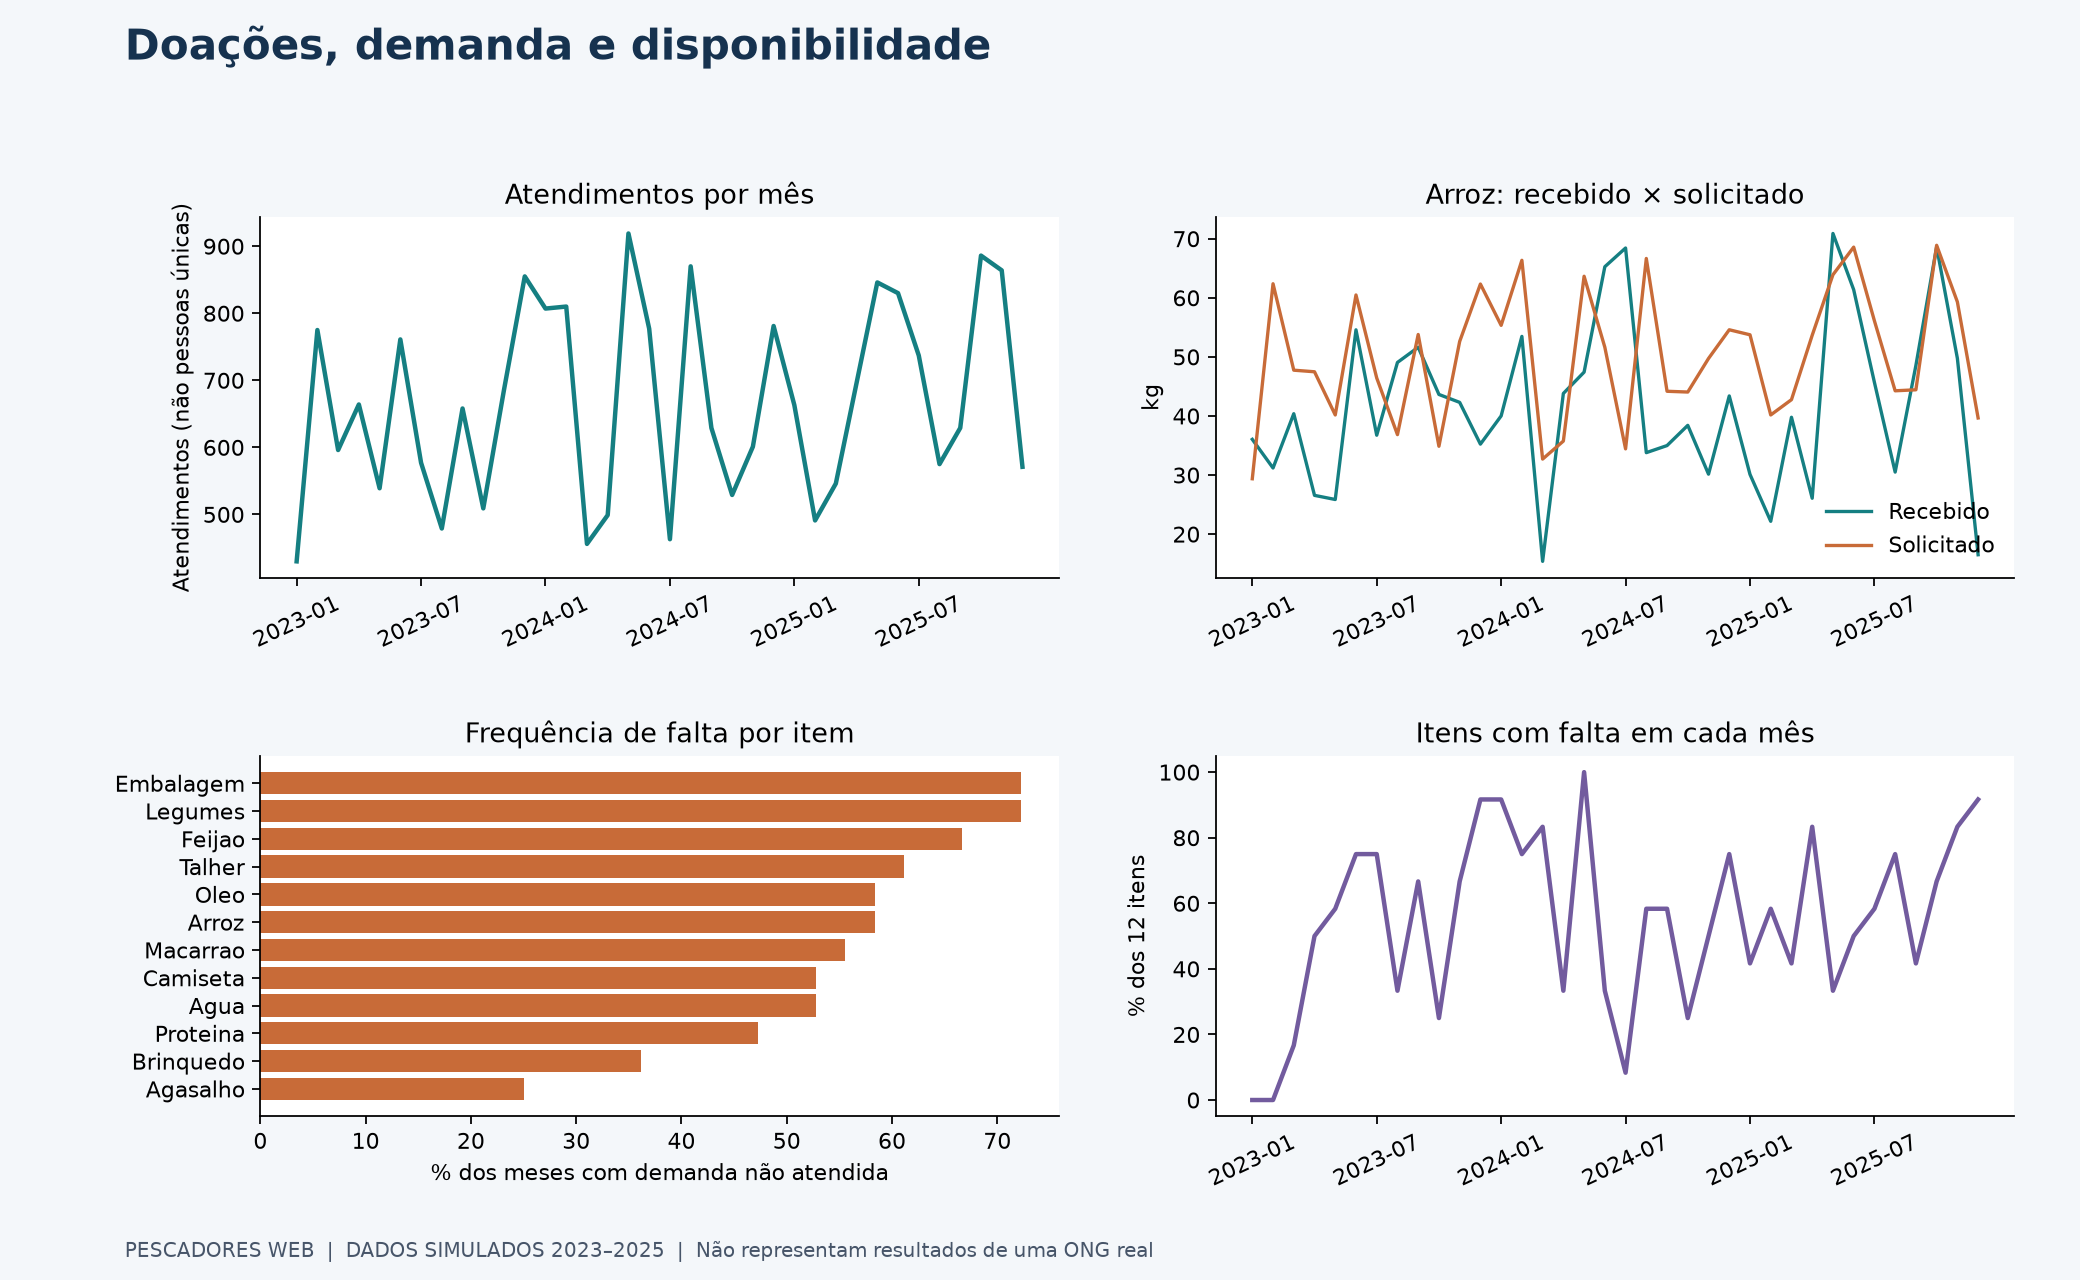

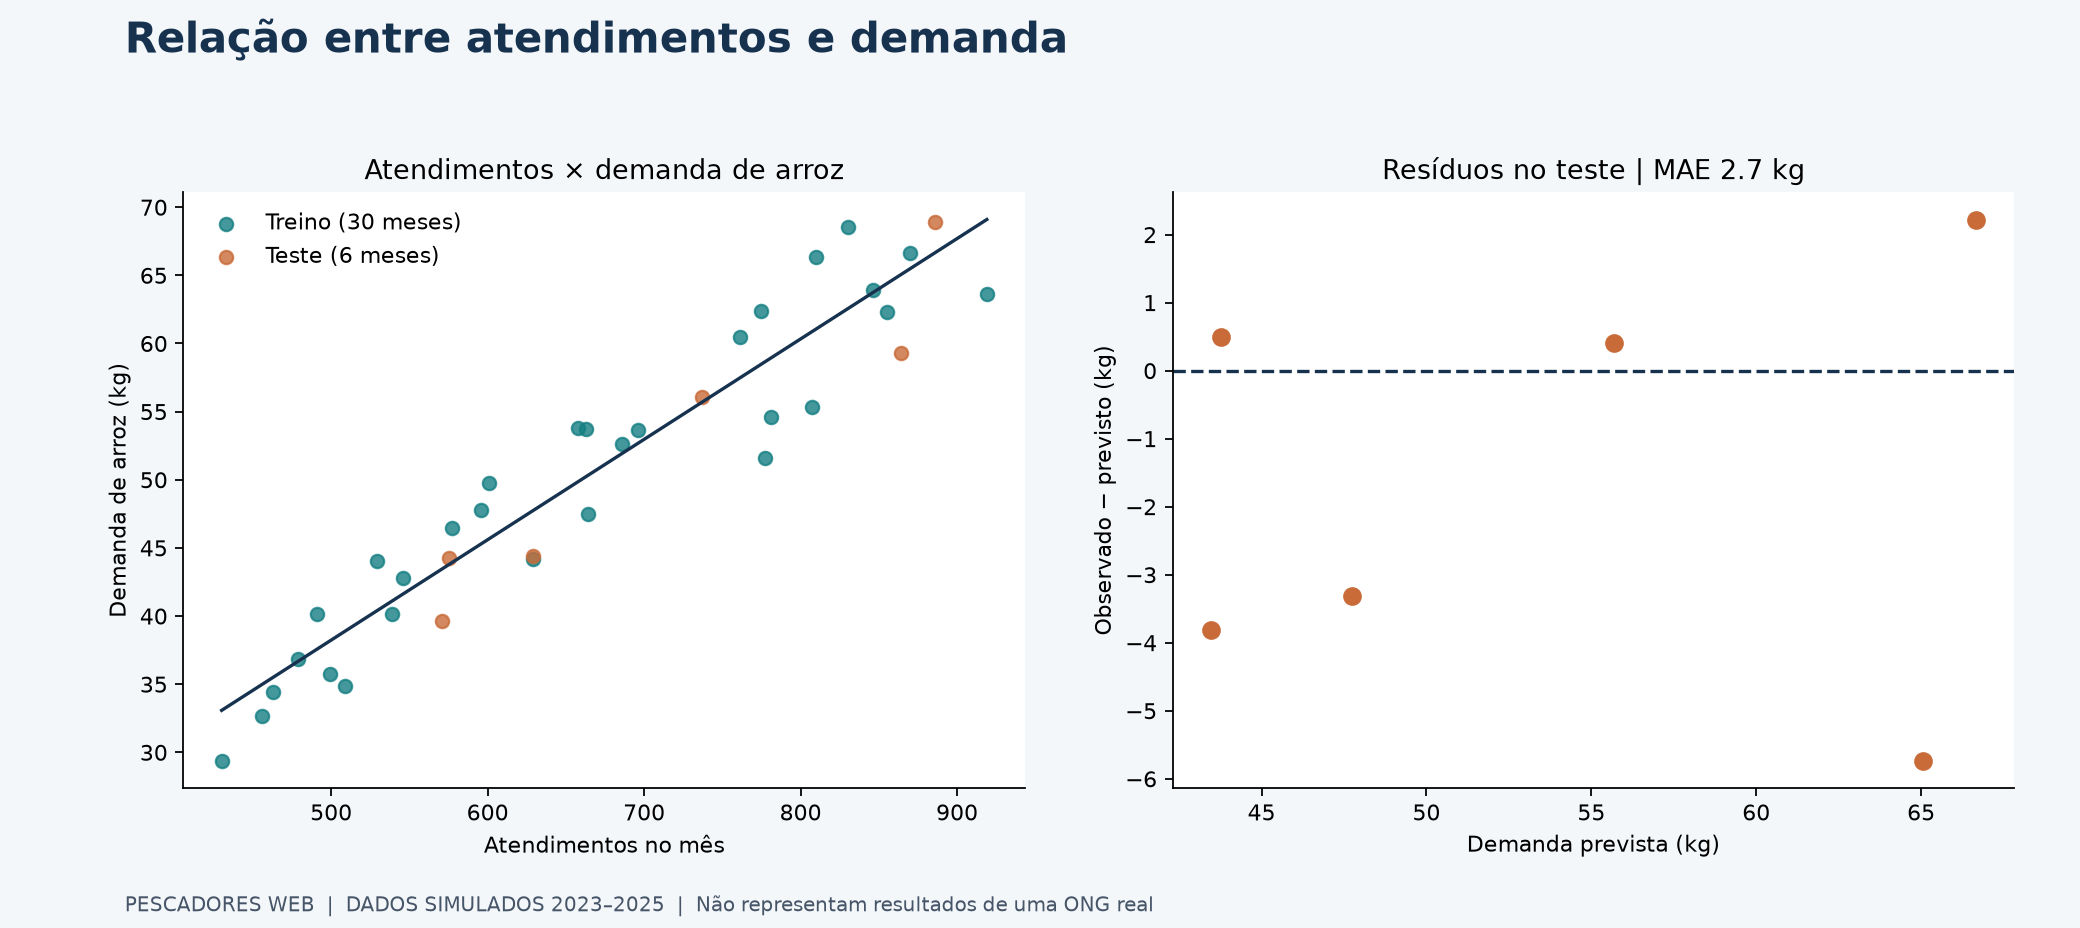

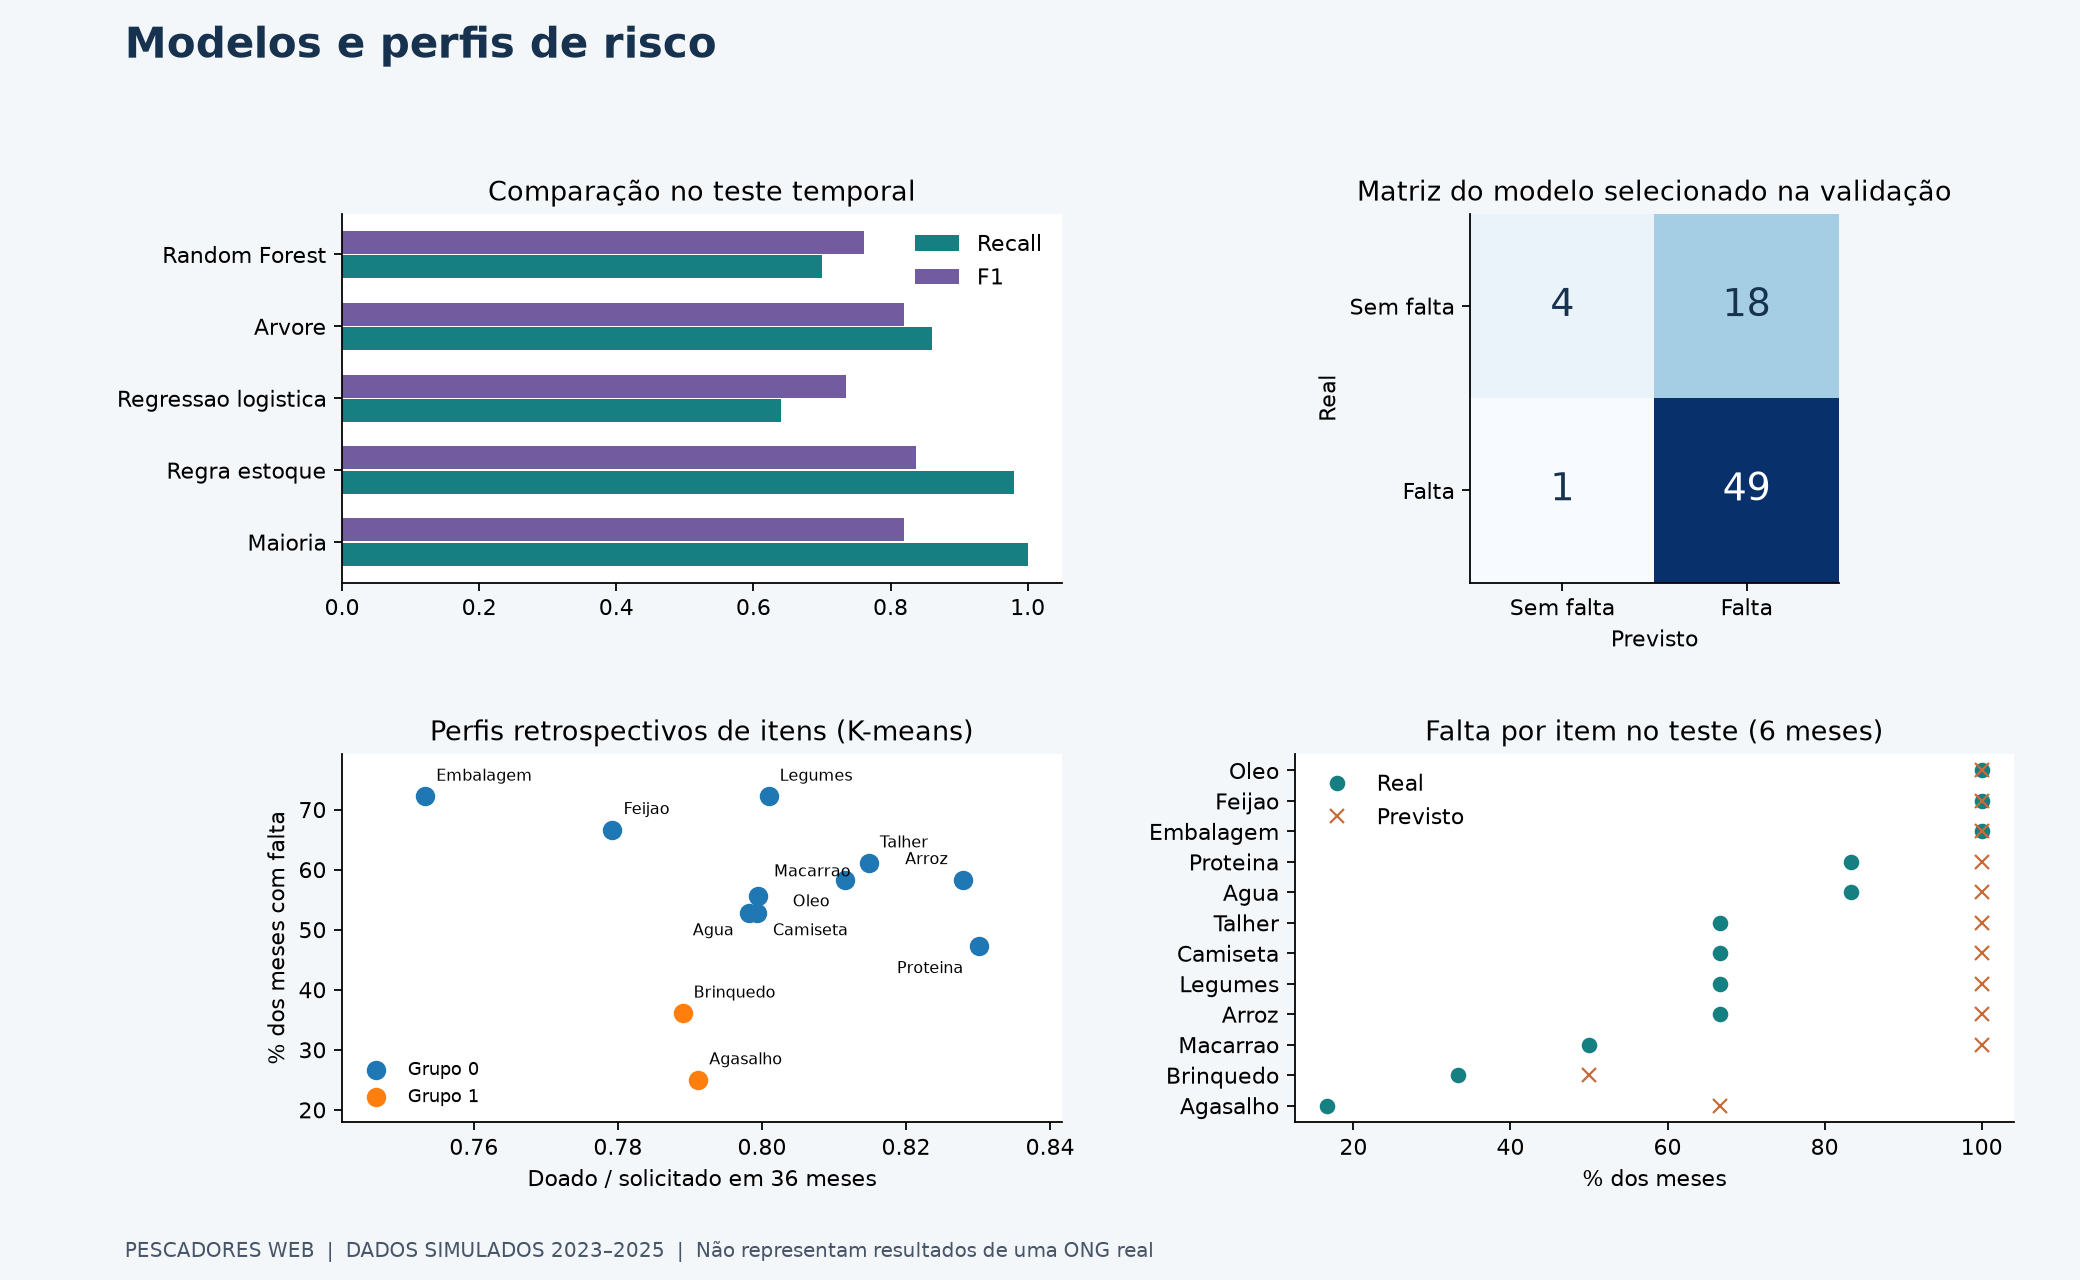

In [8]:
display(metricas_teste)
a.graficos(base, acoes, metricas_teste, predicoes, perfis, dispersao, projeto)
for nome in ["01_visao_geral.png", "02_dispersao_regressao.png", "03_modelos.png"]:
    display(Image(filename=str(projeto / "Dashboard" / nome)))


## Fase 6 — Implementação proposta

Alertas demonstrativos para janeiro/2026 usam dados até dezembro/2025. Não há rótulos
de janeiro para avaliá-los. Não existe integração ao Laravel, compra ou envio de mensagens.

Monitorar completude, duplicatas e balanço; após cada mês previsto, precisão, recall
e F1 por item. Rever se houver mudança nos dados ou piora diante da regra operacional.
Definir com os gestores os custos dos erros antes de escolher um limiar real.

A próxima iteração volta às fases de dados e preparação: coletar registros reais,
incluir perdas/validade e demanda não atendida e ampliar a validação temporal.

In [9]:
display(pd.read_csv(projeto / "dados/tratados/alertas_prototipo.csv"))
resumo = a.relatar(base, acoes, qualidade, metricas_val, metricas_teste,
                   escolhido, avaliacao_k, dispersao[2], projeto)
display(Markdown((projeto / "resultados/RESULTADOS.md").read_text(encoding="utf-8")))


,item_id,nome,unidade,estoque_final,demanda_media_3m,mes_previsto,alerta_falta,modelo
0,I01,Arroz,kg,0.0,55.953333,2026-01,1,Regra estoque
1,I02,Feijao,kg,0.0,46.120000,2026-01,1,Regra estoque
2,I03,Macarrao,kg,0.0,27.223333,2026-01,1,Regra estoque
3,I04,Proteina,kg,0.0,76.236667,2026-01,1,Regra estoque
4,I05,Legumes,kg,0.0,61.103333,2026-01,1,Regra estoque
5,I06,Oleo,litro,0.0,5.770000,2026-01,1,Regra estoque
6,I07,Embalagem,unidade,0.0,760.333333,2026-01,1,Regra estoque
7,I08,Talher,unidade,0.0,774.333333,2026-01,1,Regra estoque
8,I09,Agua,litro,0.0,360.030000,2026-01,1,Regra estoque
9,I10,Camiseta,unidade,0.0,91.000000,2026-01,1,Regra estoque


# Resultados da análise do Pescadores Web

Todos os números abaixo vêm de dados simulados com semente 42. Não são
registros da ONG, nem foram extraídos do levantamento do IDIS ou do artigo HYB.

## Pergunta e unidade de análise

Como as doações recebidas se comparam à demanda das ações sociais, e é possível
antecipar falta de itens? A unidade de análise é item-mês. Há 12 itens,
36 meses, 432 item-meses, 143 ações e 24004 atendimentos.
Atendimentos podem incluir a mesma pessoa em ações diferentes.

## Qualidade dos dados

| regra | removidas |
| --- | --- |
| duplicata_doacao_id | 1 |
| quantidade_nula | 1 |
| quantidade_nao_positiva | 1 |
| item_inexistente | 1 |
| mes_fora_do_periodo | 1 |

Os erros foram inseridos de propósito. Cada registro é removido na primeira regra
que viola; as contagens são sequenciais. Ausência de doação não pode ser confundida
com dado perdido em uma futura base real.

## Análise exploratória e regressão

54.9% dos item-meses apresentaram demanda não
atendida. Esse percentual conta item-meses, sem somar kg, litros e unidades.
Para arroz: demanda = 0.0737 × atendimentos + 1.41 kg.
O ajuste usa 30 meses; nos 6 meses finais, MAE =
2.66 kg e R² = 0.898. O simulador já liga demanda a
atendimentos: o resultado ilustra a técnica, sem constituir descoberta sobre a ONG.

## Classificação de falta no mês seguinte

As variáveis terminam no mês t e o alvo pertence a t+1. O corte é pelo mês do alvo:
treino até dez./2024 (252 linhas), validação jan.–jun./2025 (72),
teste jul.–dez./2025 (72, 50 positivos). Não há divisão aleatória.
Os mesmos itens aparecem ao longo do tempo: avalia-se previsão futura para itens
conhecidos, não generalização para outras ONGs ou novos itens.

Validação usada para selecionar por F1, com limiar fixo de 0,5:

| modelo | acuracia | precisao | recall | f1 | auc_roc | pr_auc_ap |
| --- | --- | --- | --- | --- | --- | --- |
| Maioria | 0.514 | 0.514 | 1.000 | 0.679 | 0.500 | 0.514 |
| Regra estoque | 0.569 | 0.545 | 0.973 | 0.699 | 0.558 | 0.545 |
| Regressao logistica | 0.597 | 0.577 | 0.811 | 0.674 | 0.581 | 0.584 |
| Arvore | 0.583 | 0.578 | 0.703 | 0.634 | 0.572 | 0.547 |
| Random Forest | 0.611 | 0.596 | 0.757 | 0.667 | 0.649 | 0.584 |

Modelo selecionado antes de consultar o teste: **Regra estoque**. Os modelos são
reajustados em treino + validação e o teste final é usado apenas para avaliação:

| modelo | acuracia | precisao | recall | f1 | auc_roc | pr_auc_ap |
| --- | --- | --- | --- | --- | --- | --- |
| Maioria | 0.694 | 0.694 | 1.000 | 0.820 | 0.500 | 0.694 |
| Regra estoque | 0.736 | 0.731 | 0.980 | 0.838 | 0.581 | 0.731 |
| Regressao logistica | 0.681 | 0.865 | 0.640 | 0.736 | 0.803 | 0.904 |
| Arvore | 0.736 | 0.782 | 0.860 | 0.819 | 0.743 | 0.854 |
| Random Forest | 0.694 | 0.833 | 0.700 | 0.761 | 0.786 | 0.902 |

Precisão mede a proporção dos alertas que se confirmam; recall mede a proporção das
faltas detectadas. F1 combina ambos. Acurácia pode esconder a classe minoritária.
PR-AUC é apresentada como average precision (AP). O período de teste é curto, com
observações repetidas por item; diferenças pequenas não demonstram superioridade
estatística. Se uma regra simples vencer, ela permanece como escolha do protótipo.

## Perfis de itens

K-means compara k = 2, 3 e 4 após padronização de três atributos adimensionais.
Escolhido k = 2, silhueta = 0.603. São apenas 12
itens. Os grupos são exploratórios e retrospectivos, calculados sobre 2023–2025;
não entram nas características do classificador e não são previsão validada.

## Uso proposto e limitações

`dados/tratados/alertas_prototipo.csv` demonstra alertas para jan./2026 usando dados
até dez./2025. Não há resultados observados de janeiro para avaliar esses alertas.
Um gestor poderia revisar os itens sinalizados e decidir sobre campanhas; o
protótipo não compra itens, não envia mensagens e não está integrado ao Laravel.

A simulação assume que todas as doações do mês estão disponíveis antes do consumo,
estoque sem perdas ou validade e demanda solicitada registrada mesmo quando não
atendida. Uma aplicação real exige movimentação por data, registro de perdas,
histórico suficiente e validação com os gestores. Não inferimos aumento de doações,
redução de desperdício ou impacto social a partir deste exercício.

## Monitoramento proposto

Acompanhar mensalmente completude, duplicatas, integridade dos itens e balanço de
estoque; comparar distribuição de demanda e doações com o histórico; após o mês
previsto, calcular precisão, recall, F1 e taxa de alertas por item. Investigar duas
quedas consecutivas de F1 abaixo da regra operacional, sem retreino automático.
Definir com os gestores custo de falso alerta e de falta não detectada antes de
escolher um limiar de uso real.


## Conclusão e referências

O exercício demonstra limpeza, indicadores, gráficos, regressão, agrupamento e
avaliação temporal de alertas. A utilidade real exige validação com dados operacionais.
Não inferimos aumento de doações, redução de desperdício ou impacto social.

Fontes: `docs/REFERENCIAS.md`. Dicionário: `docs/DICIONARIO_DADOS.md`.
O plano complementar distingue a construção do sistema do TCC da análise de seus dados.